# 🔷Análisis: resultados 1 y 3
**Objetivo:**
- **Resultado 1 (riesgo de dependencia):** medir cuánto se concentran las importaciones de chips de España por país de origen (HHI, CR3, número equivalente de proveedores, análisis ABC) y si ha aumentado el peso de Asia (prueba U de Mann-Whitney). Contrasta H1: *el origen de los chips importados por España está concentrado en pocos países, y una parte importante es asiática*.
- **Resultado 3 (selección de proveedores):** matriz ABC-XYZ de los países de origen, puntuación ponderada y reparto de la demanda prevista. Contrasta H3: *existen proveedores alternativos con volumen y estabilidad suficientes para repartir la demanda*.

**Datos:** tablas del modelo de `datos/procesados` (salida de `2_ modelo_datos.ipynb`). Fuente principal: Datacomex (país de origen); comparación: Comext (país de expedición). Solo bloque `chips` y países reales (sin no especificados). Valor en euros corrientes.

**Periodo:** años completos, **enero 2015 – diciembre 2025**. 2026 (enero–agosto) se deja fuera del análisis porque está incompleto y es provisional; se usa solo para comprobar la previsión (`4_prevision.ipynb`). 2024 y 2025 también son datos provisionales.

In [1]:
# Instalar una sola vez: pandas, numpy, matplotlib y scipy (prueba de Mann-Whitney)
# %pip install pandas numpy matplotlib scipy

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:,.2f}".format)
PROC = Path("datos/procesados")

# Lectura de las tablas del modelo: códigos como texto y solo lo vacío como NaN ("NA" = Namibia se mantiene)
CODIGOS = {"id_pais": str, "partner": str, "codigo": str, "familia": str, "partida": str,
           "rama_codigo": str, "nace": str}

def leer(nombre):
    ruta = PROC / f"{nombre}.csv"
    columnas = pd.read_csv(ruta, nrows=0).columns
    return pd.read_csv(ruta, dtype=CODIGOS, keep_default_na=False, na_values=[""],
                       parse_dates=["fecha"] if "fecha" in columnas else False)

## ✅Paso 0. Carga y preparación
**Enunciado:** Leer los hechos y las dimensiones, unir a cada fila su bloque y los datos del país, y quedarse con los chips de países reales: por origen (Datacomex) y por expedición (Comext).

In [3]:
FIN = "2025-12-01"          # último mes del análisis: años completos 2015-2025 (2026 está incompleto)

hechos_origen = leer("hechos_origen")
hechos_expedicion = leer("hechos_expedicion_es")
dim_producto = leer("dim_producto")
dim_pais_origen = leer("dim_pais_origen")
dim_socio = leer("dim_socio_comext")

# Unir atributos desde las dimensiones (modelo en estrella)
origen = (hechos_origen
          .merge(dim_producto[["codigo", "bloque"]], on="codigo")
          .merge(dim_pais_origen[["id_pais", "pais", "tipo_socio", "ue", "region"]], on="id_pais"))
expedicion = (hechos_expedicion
              .merge(dim_producto[["codigo", "bloque"]], on="codigo")
              .merge(dim_socio[["partner", "nombre", "tipo_socio", "ue"]], on="partner"))

# Solo chips, países reales (los no especificados se excluyen del HHI) y hasta diciembre de 2025
origen_chips = origen[(origen["bloque"] == "chips") & (origen["tipo_socio"] == "país")
                      & (origen["fecha"] <= FIN)].copy()
expedicion_chips = expedicion[(expedicion["bloque"] == "chips") & (expedicion["tipo_socio"] != "no especificado")
                              & (expedicion["fecha"] <= FIN)].copy()
origen_chips["anio"] = origen_chips["fecha"].dt.year
expedicion_chips["anio"] = expedicion_chips["fecha"].dt.year

print(f"Origen: {len(origen):,} filas → chips de países reales, 2015-2025: {len(origen_chips):,}")
print(f"Expedición: {len(expedicion):,} filas → chips de países reales, 2015-2025: {len(expedicion_chips):,}")

Origen: 56,947 filas → chips de países reales, 2015-2025: 44,150
Expedición: 52,893 filas → chips de países reales, 2015-2025: 41,987


## ✅Paso 1. Concentración por año: HHI, CR3 y número equivalente de proveedores
**Enunciado:** Calcular por año, con las cuotas (%) de cada país en el valor importado de chips:
- **HHI** = suma de los cuadrados de las cuotas (0–10,000);
- **CR3** = cuota de los 3 primeros países;
- **número equivalente de proveedores** = 10,000 ÷ HHI;
- **nivel** según la escala de referencia: < 1,500 baja, 1,500–1,800 moderada, 1,800–2,500 alta, > 2,500 muy alta (guías de EE. UU. de 2010 y 2023).

Se calcula por país de origen (Datacomex) y por país de expedición (Comext) para compararlos.

In [4]:
def nivel_hhi(hhi):
    return np.select([hhi < 1500, hhi < 1800, hhi < 2500], ["baja", "moderada", "alta"], default="muy alta")

def indicadores_concentracion(d, col_pais):
    """HHI, CR3 y nº equivalente por año a partir de las cuotas en valor de cada país."""
    valor = d.groupby(["anio", col_pais])["valor_eur"].sum()
    cuota = valor / valor.groupby(level="anio").transform("sum") * 100      # % de cada país en su año
    r = pd.DataFrame({
        "paises": cuota.groupby(level="anio").size(),
        "HHI": (cuota ** 2).groupby(level="anio").sum(),
        "CR3": cuota.groupby(level="anio").apply(lambda s: s.nlargest(3).sum()),
    })
    r["N_equivalente"] = 10000 / r["HHI"]
    r["nivel"] = nivel_hhi(r["HHI"])
    return r

conc_origen = indicadores_concentracion(origen_chips, "id_pais")
conc_expedicion = indicadores_concentracion(expedicion_chips, "partner")
print("Por país de ORIGEN (Datacomex)")
display(conc_origen)
print("Por país de EXPEDICIÓN (Comext)")
display(conc_expedicion)

Por país de ORIGEN (Datacomex)


,paises,HHI,CR3,N_equivalente,nivel
anio,,,,,
2015,98,"1,021.83",41.78,9.79,baja
2016,99,"1,102.25",45.73,9.07,baja
2017,107,"1,305.45",52.57,7.66,baja
2018,107,"1,412.65",53.30,7.08,baja
2019,107,"1,401.37",53.93,7.14,baja
2020,103,"1,604.40",60.03,6.23,moderada
2021,107,"1,658.34",62.53,6.03,moderada
2022,103,"1,338.59",59.46,7.47,baja
2023,110,"1,355.34",58.37,7.38,baja


Por país de EXPEDICIÓN (Comext)


,paises,HHI,CR3,N_equivalente,nivel
anio,,,,,
2015,99,"1,570.90",56.65,6.37,moderada
2016,95,"1,687.62",57.71,5.93,moderada
2017,106,"1,694.57",60.13,5.90,moderada
2018,107,"1,769.56",59.66,5.65,moderada
2019,114,"1,680.39",58.73,5.95,moderada
2020,102,"1,899.61",61.00,5.26,alta
2021,114,"1,946.25",63.35,5.14,alta
2022,103,"1,609.77",61.68,6.21,moderada
2023,108,"2,011.91",64.90,4.97,alta


In [5]:
# Periodo completo (2015-2025) y los 3 primeros países de cada fuente
for nombre, d, col_pais, col_nombre in [("Origen", origen_chips, "id_pais", "pais"),
                                        ("Expedición", expedicion_chips, "partner", "partner")]:
    cuota = d.groupby(col_nombre)["valor_eur"].sum()
    cuota = cuota / cuota.sum() * 100
    hhi = (cuota ** 2).sum()
    print(f"{nombre}: HHI {hhi:,.2f} ({nivel_hhi(hhi)}) | CR3 {cuota.nlargest(3).sum():.2f} % | "
          f"N equivalente {10000 / hhi:.2f} | top 3: {cuota.nlargest(3).round(2).to_dict()}")

Origen: HHI 1,290.03 (baja) | CR3 55.48 % | N equivalente 7.75 | top 3: {'Alemania': 26.51, 'Países Bajos': 14.66, 'China': 14.3}
Expedición: HHI 1,796.59 (moderada) | CR3 59.37 % | N equivalente 5.57 | top 3: {'DE': 37.16, 'NL': 15.33, 'JP': 6.87}


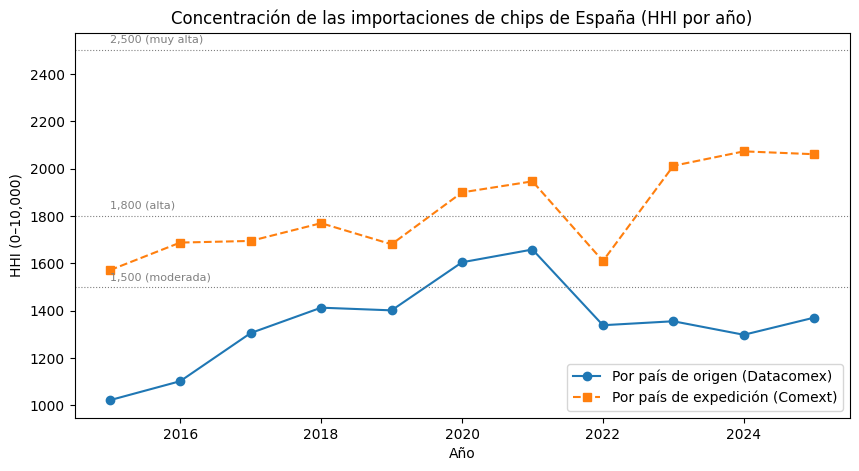

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(conc_origen.index, conc_origen["HHI"], marker="o", label="Por país de origen (Datacomex)")
ax.plot(conc_expedicion.index, conc_expedicion["HHI"], marker="s", linestyle="--", label="Por país de expedición (Comext)")
for limite, texto in [(1500, "1,500 (moderada)"), (1800, "1,800 (alta)"), (2500, "2,500 (muy alta)")]:
    ax.axhline(limite, color="grey", linewidth=0.8, linestyle=":")
    ax.text(2015, limite + 30, texto, fontsize=8, color="grey")
ax.set_title("Concentración de las importaciones de chips de España (HHI por año)")
ax.set_xlabel("Año")
ax.set_ylabel("HHI (0–10,000)")
ax.legend()
plt.show()

**Qué países hay detrás:** cuota (%) de cada país en el valor de chips por año, para los 10 primeros del periodo completo, con su región.

In [7]:
# Cuota (%) de cada país de origen por año
valor = origen_chips.groupby(["anio", "pais"])["valor_eur"].sum()
cuota_anual = (valor / valor.groupby(level="anio").transform("sum") * 100).unstack("anio").fillna(0)

# Los 10 primeros del periodo completo, con su región y su cuota total
total = origen_chips.groupby("pais")["valor_eur"].sum()
cuota_total = (total / total.sum() * 100).sort_values(ascending=False)
region = origen_chips.drop_duplicates("pais").set_index("pais")["region"]

top10 = cuota_anual.loc[cuota_total.index[:10]]
top10.insert(0, "region", region)
top10.insert(1, "% 2015-2025", cuota_total)
top10

anio,region,% 2015-2025,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
pais,,,,,,,,,,,,,
Alemania,UE,26.51,19.68,22.68,26.59,29.08,28.41,32.68,32.29,22.20,26.74,25.83,26.84
Países Bajos,UE,14.66,11.05,10.90,12.89,12.62,13.31,15.53,18.04,16.49,16.92,14.26,14.48
China,Asia,14.30,9.35,10.37,8.71,11.60,12.21,11.82,12.20,20.77,14.72,16.96,17.37
Japón,Asia,7.94,10.97,12.15,13.09,11.41,11.05,8.31,8.30,6.69,5.53,4.45,4.65
Estados Unidos,resto,5.83,10.33,10.23,10.42,8.56,9.12,5.04,3.77,4.41,3.60,3.34,3.67
Taiwán,Asia,4.03,3.52,1.99,2.01,2.07,1.98,2.68,2.96,3.50,6.12,6.36,6.32
Malasia,Asia,3.82,2.74,1.98,1.48,1.78,2.15,2.28,2.88,5.26,4.72,5.60,5.95
Francia,UE,3.60,2.97,4.51,4.25,3.96,4.02,3.76,5.23,3.99,3.22,2.43,2.54
Reino Unido,resto,2.98,11.05,7.05,6.04,5.75,5.06,4.54,0.78,0.58,0.78,0.47,0.55


### Qué países hay detrás de la concentración
**Enunciado:** Ver la cuota (%) de cada país en el valor de chips por año, para los 10 primeros del periodo completo, por país de origen (Datacomex, con su región) y por país de expedición (Comext, con UE / terceros países). Así se ve qué países explican el HHI y cómo cambian en el tiempo.

In [8]:
def cuotas_por_anio(d, col_pais, col_grupo, n=10):
    """Cuota (%) de cada país por año para los n primeros del periodo completo, con su grupo (región o UE)."""
    valor = d.groupby(["anio", col_pais])["valor_eur"].sum()
    cuota_anual = (valor / valor.groupby(level="anio").transform("sum") * 100).unstack("anio").fillna(0)
    total = d.groupby(col_pais)["valor_eur"].sum()
    cuota_total = (total / total.sum() * 100).sort_values(ascending=False)
    grupo = d.drop_duplicates(col_pais).set_index(col_pais)[col_grupo]
    tabla = cuota_anual.loc[cuota_total.index[:n]]
    tabla.insert(0, col_grupo, grupo)
    tabla.insert(1, "% 2015-2025", cuota_total)
    return tabla

print("Por país de ORIGEN (Datacomex)")
display(cuotas_por_anio(origen_chips, "pais", "region"))
print("Por país de EXPEDICIÓN (Comext; código ISO del país)")
display(cuotas_por_anio(expedicion_chips, "partner", "ue"))

Por país de ORIGEN (Datacomex)


anio,region,% 2015-2025,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
pais,,,,,,,,,,,,,
Alemania,UE,26.51,19.68,22.68,26.59,29.08,28.41,32.68,32.29,22.20,26.74,25.83,26.84
Países Bajos,UE,14.66,11.05,10.90,12.89,12.62,13.31,15.53,18.04,16.49,16.92,14.26,14.48
China,Asia,14.30,9.35,10.37,8.71,11.60,12.21,11.82,12.20,20.77,14.72,16.96,17.37
Japón,Asia,7.94,10.97,12.15,13.09,11.41,11.05,8.31,8.30,6.69,5.53,4.45,4.65
Estados Unidos,resto,5.83,10.33,10.23,10.42,8.56,9.12,5.04,3.77,4.41,3.60,3.34,3.67
Taiwán,Asia,4.03,3.52,1.99,2.01,2.07,1.98,2.68,2.96,3.50,6.12,6.36,6.32
Malasia,Asia,3.82,2.74,1.98,1.48,1.78,2.15,2.28,2.88,5.26,4.72,5.60,5.95
Francia,UE,3.60,2.97,4.51,4.25,3.96,4.02,3.76,5.23,3.99,3.22,2.43,2.54
Reino Unido,resto,2.98,11.05,7.05,6.04,5.75,5.06,4.54,0.78,0.58,0.78,0.47,0.55


Por país de EXPEDICIÓN (Comext; código ISO del país)


anio,ue,% 2015-2025,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
partner,,,,,,,,,,,,,
DE,UE,37.16,32.57,35.27,34.94,36.55,35.18,38.57,37.93,32.10,39.12,41.22,41.13
NL,UE,15.33,11.70,11.46,13.08,12.52,13.48,15.07,17.92,18.18,18.39,15.33,15.04
JP,terceros países,6.87,10.02,10.99,12.12,10.59,10.07,7.36,6.94,5.54,4.27,3.61,3.51
CN,terceros países,6.81,2.94,2.59,4.16,7.08,6.91,6.01,7.50,11.41,7.39,6.75,6.48
FR,UE,5.25,5.24,8.15,7.60,7.09,6.07,4.96,6.41,4.80,3.69,3.94,3.77
CZ,UE,3.68,6.28,4.66,1.93,2.07,2.37,2.70,2.79,2.28,4.01,4.67,5.86
US,terceros países,3.28,4.05,3.46,4.09,3.27,3.24,3.13,3.18,3.67,2.81,2.70,3.21
GB,terceros países,3.26,12.38,8.27,6.64,5.69,5.29,4.65,0.87,0.63,0.83,0.55,0.77
BE,UE,2.59,0.50,0.68,0.66,0.86,3.93,3.98,2.77,2.92,3.75,3.07,2.94


**Tendencia de los principales países de origen:** evolución de la cuota (%) en el valor de chips de los 7 primeros países de origen del periodo completo. El estilo de la línea indica la región (continua: UE; discontinua: Asia; punteada: resto). 

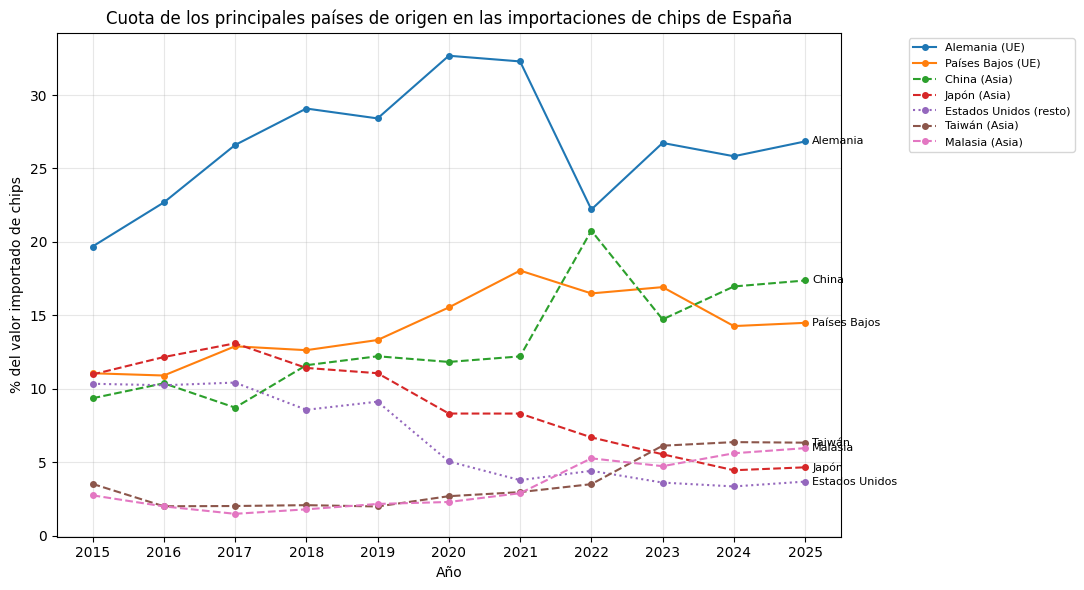

In [9]:
tabla_origen = cuotas_por_anio(origen_chips, "pais", "region", n=7)
anios = [c for c in tabla_origen.columns if isinstance(c, (int, np.integer))]
estilo_region = {"UE": "-", "Asia": "--", "resto": ":"}

fig, ax = plt.subplots(figsize=(11, 6))
for pais, fila in tabla_origen.iterrows():
    ax.plot(anios, fila[anios], marker="o", markersize=4,
            linestyle=estilo_region[fila["region"]], label=f"{pais} ({fila['region']})")
    ax.annotate(pais, (anios[-1], fila[anios[-1]]), xytext=(5, 0),
                textcoords="offset points", fontsize=8, va="center")

ax.set_title("Cuota de los principales países de origen en las importaciones de chips de España")
ax.set_xlabel("Año")
ax.set_ylabel("% del valor importado de chips")
ax.set_xticks(anios)
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.08, 1))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**📌Conclusión:**
- **Concentración por origen baja o moderada:** el HHI por país de origen está entre 1,021.83 (2015) y 1,658.34 (2021); en el periodo completo (2015–2025) es 1,290.03 (baja), con un CR3 del 55.48 % y 7.75 proveedores equivalentes. El máximo coincide con la crisis de chips (2020–2021, nivel moderado) y después baja (entre 1,298.19 y 1,370.82 en 2022–2025).
- **Por expedición es más alta:** HHI de 1,796.59 en el periodo completo (moderada, justo por debajo del umbral de 1,800), CR3 del 59.37 % y 5.57 proveedores equivalentes; desde 2023 está todos los años en el nivel alto (por encima de 2,000). España compra a pocos países de expedición, sobre todo Alemania (37.16 %) y Países Bajos (15.33 %), pero los chips se fabrican en más países.
- **Países de origen principales (2015–2025):** Alemania 26.51 %, Países Bajos 14.66 %, China 14.30 %, Japón 7.94 %, Estados Unidos 5.83 %, Taiwán 4.03 % y Malasia 3.82 %.
- **Cambios en el tiempo (origen):**
  - Suben los países asiáticos: China pasa del 9.35 % (2015) a más del 17 % en 2024–2025 (máximo en 2022); Taiwán y Malasia aumentan sobre todo desde 2022.
  - Bajan Japón (del 10.97 % en 2015 a menos del 5 % en 2024–2025), Estados Unidos (del 10.33 % a menos del 4 %) y Reino Unido (por debajo del 1 % desde 2021).
  - Alemania se mantiene como primer país de origen en todo el periodo.
- **Gráfico de tendencia:** se ve el cambio de peso entre regiones: las líneas de los países asiáticos (China, Taiwán, Malasia) suben, sobre todo desde 2022, mientras bajan Japón y Estados Unidos; Alemania se mantiene arriba en todo el periodo.
- **Para H1:** con el HHI por origen, la concentración no llega a ser alta, aunque los 3 primeros países suman más de la mitad del valor. La parte asiática se contrasta en el paso 3.

## ✅Paso 2. Análisis ABC (Pareto) de los países de origen
**Enunciado:** Ordenar los países de origen por su cuota en el valor de chips (2015–2025) y clasificarlos según la cuota acumulada: **A** = países que suman el primer 80 % del valor, **B** = el 15 % siguiente (hasta el 95 %), **C** = el 5 % restante. Muestra cuántos países concentran la mayor parte de las compras.

In [10]:
total = origen_chips.groupby("pais")["valor_eur"].sum().sort_values(ascending=False)
abc = pd.DataFrame({"cuota": total / total.sum() * 100})
abc["cuota_acumulada"] = abc["cuota"].cumsum()
anterior = abc["cuota_acumulada"] - abc["cuota"]              # acumulado antes de sumar ese país
abc["clase"] = np.select([anterior < 80, anterior < 95], ["A", "B"], default="C")
abc["region"] = origen_chips.drop_duplicates("pais").set_index("pais")["region"]

resumen_abc = abc.groupby("clase").agg(paises=("cuota", "size"), cuota=("cuota", "sum"))
display(resumen_abc)
abc[abc["clase"] == "A"]

,paises,cuota
clase,,
A,8,80.70
B,11,14.67
C,169,4.63


,cuota,cuota_acumulada,clase,region
pais,,,,
Alemania,26.51,26.51,A,UE
Países Bajos,14.66,41.18,A,UE
China,14.30,55.48,A,Asia
Japón,7.94,63.42,A,Asia
Estados Unidos,5.83,69.25,A,resto
Taiwán,4.03,73.28,A,Asia
Malasia,3.82,77.10,A,Asia
Francia,3.60,80.70,A,UE


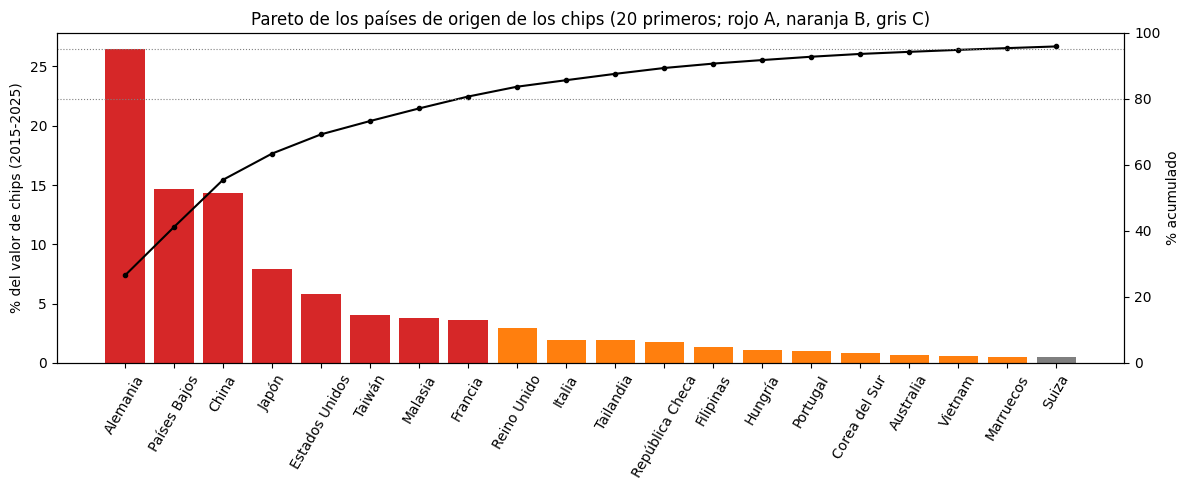

In [11]:
top = abc.head(20)
colores = top["clase"].map({"A": "tab:red", "B": "tab:orange", "C": "tab:grey"})

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(top.index, top["cuota"], color=colores)
ax.set_ylabel("% del valor de chips (2015-2025)")
ax.tick_params(axis="x", rotation=60)
ax2 = ax.twinx()
ax2.plot(top.index, top["cuota_acumulada"], color="black", marker="o", markersize=3)
ax2.axhline(80, color="grey", linestyle=":", linewidth=0.8)
ax2.axhline(95, color="grey", linestyle=":", linewidth=0.8)
ax2.set_ylabel("% acumulado")
ax2.set_ylim(0, 100)
ax.set_title("Pareto de los países de origen de los chips (20 primeros; rojo A, naranja B, gris C)")
plt.tight_layout()
plt.show()

**📌Conclusión:**
- Clase A: 8 países concentran el 80.70 % del valor de chips (2015–2025): Alemania, Países Bajos, China, Japón, Estados Unidos, Taiwán, Malasia y Francia. Cuatro de los ocho son asiáticos (China, Japón, Taiwán y Malasia: 30.09 % del valor entre los cuatro).
- Clase B: 11 países (14.67 %). Clase C: 169 países (4.63 %).
- Con solo 8 de 188 países se cubre el 81 % del valor importado: unos pocos países explican casi todas las compras, aunque ninguno domina (el HHI por origen es bajo-moderado porque las cuotas de los países A están repartidas).

## ✅Paso 3. Peso de Asia como origen: cuotas por región y prueba U de Mann-Whitney
**Enunciado:** Calcular la cuota de cada región de origen (UE, Asia, resto) en el valor de chips por año y por periodo, y contrastar si ha aumentado el peso de Asia.
- **Pregunta:** ¿es mayor la cuota de Asia en el valor importado de chips en 2022–2025 que en 2015–2021?
- **H₀:** la cuota mensual de Asia es igual en los dos periodos. **H₁:** es mayor en 2022–2025.
- **Prueba:** U de Mann-Whitney (no paramétrica, unilateral, α = 0.05) sobre la cuota de Asia de cada mes (84 meses frente a 48).

No se usa el chi-cuadrado porque solo es válido con conteos, no con valores en euros (ver Metodología, decisión 2.8).

In [12]:
# Cuota (%) de cada región por año y por periodo
valor_region = origen_chips.groupby(["anio", "region"])["valor_eur"].sum().unstack("region")
cuota_region_anual = valor_region.div(valor_region.sum(axis=1), axis=0) * 100
display(cuota_region_anual)

origen_chips["periodo"] = np.where(origen_chips["anio"] <= 2021, "2015-2021", "2022-2025")
valor_periodo = origen_chips.groupby(["periodo", "region"])["valor_eur"].sum().unstack("region")
cuota_region_periodo = valor_periodo.div(valor_periodo.sum(axis=1), axis=0) * 100
cuota_region_periodo

region,Asia,UE,resto
anio,,,
2015,30.61,45.13,24.27
2016,30.60,49.10,20.30
2017,28.08,51.94,19.98
2018,30.04,53.09,16.87
2019,30.61,53.36,16.03
2020,29.32,59.13,11.55
2021,31.64,62.06,6.30
2022,44.10,49.48,6.42
2023,38.33,55.38,6.30


region,Asia,UE,resto
periodo,,,
2015-2021,30.21,53.91,15.88
2022-2025,41.72,51.68,6.60


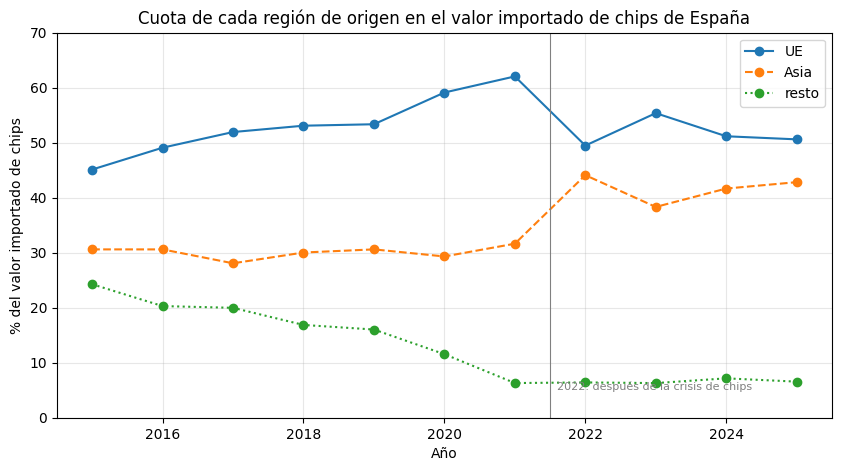

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
for region, estilo in [("UE", "-"), ("Asia", "--"), ("resto", ":")]:
    ax.plot(cuota_region_anual.index, cuota_region_anual[region], marker="o", linestyle=estilo, label=region)
ax.axvline(2021.5, color="grey", linewidth=0.8)
ax.text(2021.6, 5, "2022: después de la crisis de chips", fontsize=8, color="grey")
ax.set_title("Cuota de cada región de origen en el valor importado de chips de España")
ax.set_xlabel("Año")
ax.set_ylabel("% del valor importado de chips")
ax.set_ylim(0, 70)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [14]:
from scipy.stats import mannwhitneyu

# Cuota de Asia en cada mes
valor_mes = origen_chips.groupby(["fecha", "region"])["valor_eur"].sum().unstack("region")
cuota_asia_mes = valor_mes["Asia"] / valor_mes.sum(axis=1) * 100

antes = cuota_asia_mes[cuota_asia_mes.index < "2022-01-01"]       # 2015-2021: 84 meses
despues = cuota_asia_mes[cuota_asia_mes.index >= "2022-01-01"]    # 2022-2025: 48 meses

resultado = mannwhitneyu(despues, antes, alternative="greater")   # H1: después > antes
print(f"Meses: {len(antes)} (2015-2021) y {len(despues)} (2022-2025)")
print(f"Mediana de la cuota de Asia: {antes.median():.2f} % → {despues.median():.2f} %")
print(f"U = {resultado.statistic:,.2f} | p-valor = {resultado.pvalue:.2e}")
print("Se rechaza H0: la cuota de Asia es mayor en 2022-2025" if resultado.pvalue < 0.05
      else "No se rechaza H0")

Meses: 84 (2015-2021) y 48 (2022-2025)
Mediana de la cuota de Asia: 29.78 % → 40.56 %
U = 3,956.00 | p-valor = 2.26e-20
Se rechaza H0: la cuota de Asia es mayor en 2022-2025


**📌Conclusión:**
- La UE es la primera región de origen en todo el periodo (52–54 % del valor de chips), seguida de Asia.
- El peso de Asia aumenta tras la crisis de chips: del 30.21 % del valor en 2015–2021 al 41.72 % en 2022–2025. El salto se produce en 2022 (44.10 %) y se mantiene (38–43 %); el resto del mundo baja del 15.88 % al 6.60 % (sobre todo Estados Unidos y Reino Unido).
- Prueba U de Mann-Whitney (unilateral, 84 meses frente a 48): la cuota mensual de Asia es mayor en 2022–2025 (mediana 40.56 % frente a 29.78 %; U = 3,956.00; p = 2.26e-20). Se rechaza H₀.
- Para H1: una parte importante del origen de los chips es asiática (42 % del valor en 2022–2025) y ha crecido de forma significativa.
- Limitación: los meses seguidos no son del todo independientes (autocorrelación), por lo que el p-valor puede ser algo optimista; con una diferencia de 11 puntos, la conclusión no cambia.

# Resultado 3: selección de proveedores
## ✅Paso 4. Matriz ABC-XYZ de los países de origen
**Enunciado:** Clasificar **todos** los países de origen de los chips con dos criterios, sobre **enero 2023 – diciembre 2025** (36 meses, tres años naturales completos):
- **ABC (importancia, en €):** cuota de cada país en el valor; A = primer 80 %, B = hasta el 95 %, C = resto.
- **XYZ (estabilidad, en kg):** coeficiente de variación (CV = desviación típica ÷ media) de los kg que llegan de cada país cada mes (`peso_kg_serie`). Un mes sin importaciones cuenta como 0 kg; un mes con solo peso anómalo, como desconocido.
- **Umbrales adaptados:** X ≤ 50 % (la variación mensual es menos de la mitad de la media), Y 50–100 %, Z > 100 % (varía más que su propia media). Los orientativos (10 % / 25 %) están pensados para un almacén y aquí todos los países saldrían Z (Niekurzak y Mikulik)
- **Comprobación:** CV del valor mensual en € (`cv_eur`), porque el kg mezcla productos con €/kg muy distintos.

**Por qué esta ventana:** para elegir proveedores importa la situación actual. Dentro del periodo del análisis (2015–2025) se usan los tres últimos años; se excluye 2022 (picos puntuales de acopio tras la crisis de chips que disparan el CV). La práctica usa 12–24 meses de datos mensuales para el XYZ (mínimo 12, un ciclo estacional); 36 meses cubren tres ciclos completos. 2024 y 2025 son datos provisionales.

Se adapta la matriz ABC-XYZ, habitual en la clasificación de artículos, a los países de origen (Scholz-Reiter et al., 2012; Mecalux, 2025).

In [15]:
UMBRAL_X, UMBRAL_Y = 50, 100                                  # umbrales adaptados del CV (%)

def clasificar_proveedores(d, inicio, fin):
    """ABC (en €) y XYZ (CV de los kg mensuales) de los países de origen entre dos meses."""
    meses = pd.date_range(inicio, fin, freq="MS")
    r = d[(d["fecha"] >= inicio) & (d["fecha"] <= fin)]

    # ABC: cuota en valor y clase según la cuota acumulada
    valor = r.groupby("pais")["valor_eur"].sum().sort_values(ascending=False)
    p = pd.DataFrame({"valor_eur": valor, "cuota": valor / valor.sum() * 100})
    p["cuota_acumulada"] = p["cuota"].cumsum()
    anterior = p["cuota_acumulada"] - p["cuota"]
    p["clase_abc"] = np.select([anterior < 80, anterior < 95], ["A", "B"], default="C")
    p["region"] = r.drop_duplicates("pais").set_index("pais")["region"]

    # XYZ: kg por mes (mes sin filas = 0; mes con solo peso anómalo = NaN, no cuenta)
    kg = r.groupby(["fecha", "pais"])["peso_kg_serie"].sum(min_count=1).unstack()
    hay_filas = r.groupby(["fecha", "pais"]).size().unstack().notna()
    kg = kg.where(hay_filas, 0).reindex(meses, fill_value=0)
    p["meses_con_importacion"] = (kg > 0).sum()
    p["kg_medio_mes"] = kg.mean()
    p["cv"] = kg.std() / kg.mean() * 100
    p["clase_xyz"] = np.select([p["cv"] <= UMBRAL_X, p["cv"] <= UMBRAL_Y], ["X", "Y"], default="Z")
    p["clase"] = p["clase_abc"] + p["clase_xyz"]

    # Comprobación: CV del valor mensual en €
    eur = r.groupby(["fecha", "pais"])["valor_eur"].sum().unstack().reindex(meses).fillna(0)
    p["cv_eur"] = eur.std() / eur.mean() * 100

    # €/kg mediano (para la puntuación del paso 5): filas válidas y sin peso anómalo
    validas = r[r["eur_kg_valido"] & ~r["peso_anomalo"]]
    p["eur_kg_mediano"] = validas.groupby("pais")["eur_kg"].median()
    return p

In [16]:
proveedores = clasificar_proveedores(origen_chips, "2023-01-01", "2025-12-01")

# Resumen por clase ABC
display(proveedores.groupby("clase_abc").agg(paises=("cuota", "size"), cuota=("cuota", "sum"),
                                             meses_medio=("meses_con_importacion", "mean")))

print("Distribución del CV (%) por clase ABC:")
display(proveedores.groupby("clase_abc")["cv"].describe())

# Tabla completa de los 146 países, ordenada por cuota
pd.set_option("display.max_rows", 200)
proveedores[["region", "cuota", "clase_abc", "meses_con_importacion", "kg_medio_mes", "cv", "clase_xyz",
             "clase", "cv_eur", "eur_kg_mediano"]]

,paises,cuota,meses_medio
clase_abc,,,
A,8,80.86,36.00
B,10,14.57,36.00
C,128,4.58,12.79


Distribución del CV (%) por clase ABC:


,count,mean,std,min,25%,50%,75%,max
clase_abc,,,,,,,,
A,8.00,80.01,46.24,39.39,55.18,66.92,82.45,187.24
B,10.00,84.75,34.17,33.85,66.59,76.38,99.25,144.52
C,128.00,395.24,182.94,77.34,234.48,428.87,600.00,600.00


,region,cuota,clase_abc,meses_con_importacion,kg_medio_mes,cv,clase_xyz,clase,cv_eur,eur_kg_mediano
pais,,,,,,,,,,
Alemania,UE,26.46,A,36,"976,489.81",79.97,Y,AY,12.23,64.89
China,Asia,16.31,A,36,"356,667.72",187.24,Z,AZ,39.22,146.74
Países Bajos,UE,15.25,A,36,"283,126.02",55.50,Y,AY,17.23,111.56
Taiwán,Asia,6.26,A,36,"13,908.92",39.39,X,AX,32.23,356.88
Malasia,Asia,5.41,A,36,"33,345.28",74.47,Y,AY,39.01,278.56
Japón,Asia,4.88,A,36,"37,148.28",54.23,Y,AY,28.09,202.12
Estados Unidos,resto,3.54,A,36,"7,666.81",59.36,Y,AY,26.67,"1,319.41"
Francia,UE,2.74,A,36,"96,217.71",89.90,Y,AY,27.78,120.31
Tailandia,Asia,2.43,B,36,"8,445.54",33.85,X,BX,65.64,282.90


clase_xyz,X,Y,Z,total
clase_abc,,,,
A,1,6,1,8
B,1,6,3,10
C,0,6,122,128
total,2,18,126,146


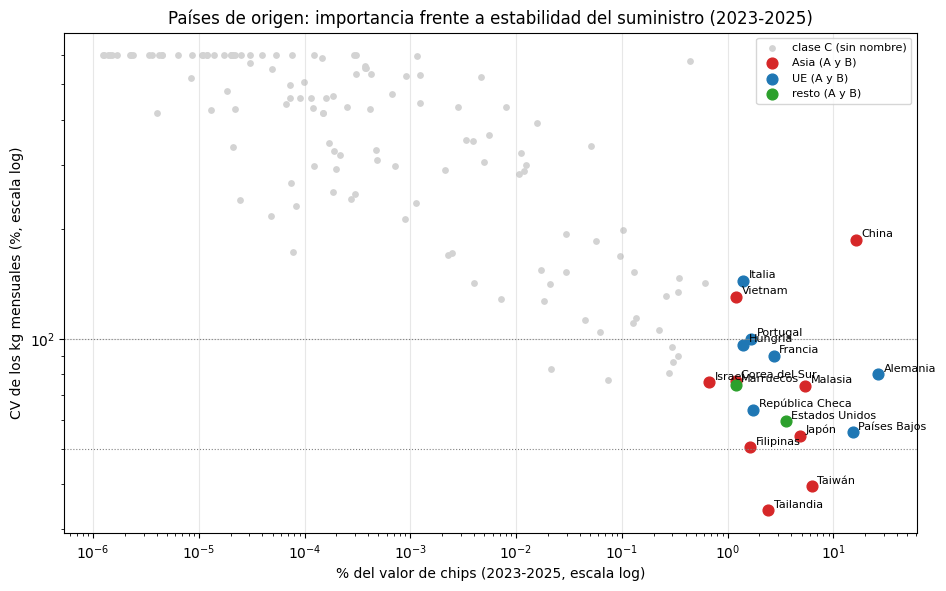

In [17]:
# Matriz ABC-XYZ con todos los países
display(pd.crosstab(proveedores["clase_abc"], proveedores["clase_xyz"], margins=True, margins_name="total"))

# Gráfico: todos los países. A y B con nombre; C en gris y sin nombre (son 128 y no se leerían)
colores = {"UE": "tab:blue", "Asia": "tab:red", "resto": "tab:green"}
fig, ax = plt.subplots(figsize=(11, 6.5))
c = proveedores[proveedores["clase_abc"] == "C"]
ax.scatter(c["cuota"], c["cv"], s=15, color="lightgrey", label="clase C (sin nombre)")
ab = proveedores[proveedores["clase_abc"].isin(["A", "B"])]
for region, grupo in ab.groupby("region"):
    ax.scatter(grupo["cuota"], grupo["cv"], s=60, color=colores.get(region, "grey"), label=f"{region} (A y B)")
    for pais, fila in grupo.iterrows():
        ax.annotate(pais, (fila["cuota"], fila["cv"]), xytext=(4, 2), textcoords="offset points", fontsize=8)
ax.axhline(UMBRAL_X, color="grey", linestyle=":", linewidth=0.8)
ax.axhline(UMBRAL_Y, color="grey", linestyle=":", linewidth=0.8)
ax.set_xscale("log")
ax.set_yscale("log")      # los países C tienen CV muy altos (hasta 600 %) y aplastarían a los demás
ax.set_xlabel("% del valor de chips (2023-2025, escala log)")
ax.set_ylabel("CV de los kg mensuales (%, escala log)")
ax.set_title("Países de origen: importancia frente a estabilidad del suministro (2023-2025)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()

In [18]:
# Comprobación de sensibilidad: misma clasificación con otra ventana que cumpla los mismos criterios
# (años completos, sin 2022 ni 2026): enero 2024 - diciembre 2025 (24 meses).
# La ventana principal sigue siendo 2023-2025; esta solo sirve para comparar.
alternativa = clasificar_proveedores(origen_chips, "2024-01-01", "2025-12-01")
sensibilidad = pd.DataFrame({"clase_abc": proveedores["clase_abc"],
                             "2023-2025": proveedores["clase"],
                             "2024-2025": alternativa["clase"].reindex(proveedores.index)})
sensibilidad["misma_clase"] = sensibilidad["2023-2025"] == sensibilidad["2024-2025"]

print("Países con la misma clase en las dos ventanas, por clase ABC:")
display(sensibilidad.groupby("clase_abc")["misma_clase"].agg(misma_clase="sum", paises="size"))
sensibilidad

Países con la misma clase en las dos ventanas, por clase ABC:


,misma_clase,paises
clase_abc,,
A,5,8
B,5,10
C,108,128


,clase_abc,2023-2025,2024-2025,misma_clase
pais,,,,
Alemania,A,AY,AY,True
China,A,AZ,AZ,True
Países Bajos,A,AY,AX,False
Taiwán,A,AX,AX,True
Malasia,A,AY,AY,True
Japón,A,AY,AX,False
Estados Unidos,A,AY,AY,True
Francia,A,AY,AZ,False
Tailandia,B,BX,BX,True


In [19]:
# ¿Se mantiene el orden de estabilidad? Correlación de Spearman entre los CV de las dos ventanas (países A y B)
cv_ventanas = pd.DataFrame({"cv_2023_2025": proveedores["cv"],
                            "cv_2024_2025": alternativa["cv"].reindex(proveedores.index)})
cv_ventanas = cv_ventanas[proveedores["clase_abc"].isin(["A", "B"])]
print(f"Correlación de Spearman del CV (países A y B): "
      f"{cv_ventanas['cv_2023_2025'].corr(cv_ventanas['cv_2024_2025'], method='spearman'):.2f}")

Correlación de Spearman del CV (países A y B): 0.88


**📌Conclusión:**
- **ABC (2023–2025, 146 países):** 8 países concentran el 80.86 % del valor (clase A): Alemania 26.46 %, China 16.31 %, Países Bajos 15.25 %, Taiwán 6.26 %, Malasia 5.41 %, Japón 4.88 %, Estados Unidos 3.54 % y Francia 2.74 %. Otros 10 países son clase B (14.57 %) y 128 son clase C (4.58 %). Respecto a 2015–2025, China pasa a ser el segundo país y Taiwán y Malasia superan a Japón.
- **Continuidad:** los 18 países A y B suministran todos los meses (36 de 36). Los países C importan de media 12.79 meses de 36; la mitad, en 5 meses o menos.
- **XYZ:** con los umbrales orientativos (10 % / 25 %) todos serían Z; con los adaptados (50 % / 100 %): 2 X, 18 Y y 126 Z. El CV mediano es 66.92 % en A, 76.38 % en B y 428.87 % en C.
- **Matriz ABC-XYZ:**

| | X | Y | Z | total |
|---|---|---|---|---|
| A | 1 | 6 | 1 | 8 |
| B | 1 | 6 | 3 | 10 |
| C | 0 | 6 | 122 | 128 |
| total | 2 | 18 | 126 | 146 |

  - **AX (importante y estable):** Taiwán (CV 39.39 %).
  - **AY (importantes, variabilidad media):** Alemania, Países Bajos, Malasia, Japón, Estados Unidos y Francia.
  - **AZ (importante e irregular, el más crítico):** China (187.24 %).
  - **BX (poca cuota pero estable):** Tailandia (33.85 %).
  - **BY:** República Checa, Filipinas, Hungría, Marruecos, Corea del Sur e Israel. **BZ:** Portugal, Italia y Vietnam.
  - **CY (6 países):** Bélgica, Hong Kong, Austria, Irlanda, Rumanía y Turquía: importan los 36 meses con variabilidad media; suministran con continuidad, aunque poco.
  - **CZ (122 países):** importan de forma esporádica (83 de ellos, en menos de 12 meses de 36); su CV alto refleja la falta de continuidad.
- **Caso de China:** su irregularidad en kg viene de unos pocos envíos muy pesados y baratos (p. ej. noviembre de 2023: 3,643 t de cristales piezoeléctricos, código 854160); en euros su CV es solo del 39.22 %. La clase Z de China indica envíos pesados puntuales más que cortes de suministro.
- **Sensibilidad (misma clase con 2023–2025 y con 2024–2025, las dos con años completos y sin 2022):** A 5 de 8, B 5 de 10, C 108 de 128. El ABC de los países A y B es idéntico. En la clase XYZ cambian 8 de los 18 países A y B: 6 porque están cerca de los umbrales (Países Bajos, Japón, Filipinas, Francia, Hungría y Portugal) y 2 por cambios reales (República Checa e Italia, con picos en 2023). El orden de los países según su CV casi no cambia (correlación de Spearman 0.88): la medida es robusta, pero las clases X/Y/Z de los países cerca de los umbrales hay que leerlas con prudencia. En la clase C, la mayoría de los cambios son países que no importaron en 2024–2025.
- **Asia en los países A y B:** 9 de los 18 son asiáticos (7 de la UE y 2 del resto).

## ✅Paso 5. Puntuación ponderada de los proveedores
**Enunciado:** Preseleccionar los países candidatos y puntuarlos con cuatro criterios ponderados, sobre la misma ventana del paso 4 (enero 2023 – diciembre 2025):
- **Preselección (lista corta):** países A y B (tienen volumen) + CY (poco volumen, pero suministran los 36 meses con variabilidad media: son alternativas). Es la fase de precalificación de la selección de proveedores (Sonmez, 2006). Los 146 países se conservan en la tabla, con la columna `candidato`.
- **Criterios:** volumen (kg medios al mes, más = mejor), estabilidad (CV de los kg mensuales como número, menos = mejor), coste (€/kg mediano, menos = mejor) y riesgo de la región de origen (UE = 1, resto = 0.5, Asia = 0).
- **Normalización por rangos:** cada criterio se pasa a percentil (0–1) dentro de los candidatos, porque las unidades son distintas y hay valores extremos (OECD, 2008).
- **Pesos:** 25 % cada criterio (supuesto explícito), con una comprobación de sensibilidad con otros pesos.
- **Resultado:** tabla `proveedores_puntuados.csv` en `datos/procesados`, que se usa para el reparto en `4_prevision.ipynb` y en Streamlit.

In [20]:
# Preselección (decisión 2.10): A y B por volumen + CY por continuidad. Los 146 se conservan.
proveedores["candidato"] = proveedores["clase_abc"].isin(["A", "B"]) | (proveedores["clase"] == "CY")
candidatos = proveedores[proveedores["candidato"]].copy()

print(f"Candidatos: {len(candidatos)} de {len(proveedores)} países "
      f"({candidatos['cuota'].sum():.2f} % del valor de 2023-2025)")
display(pd.crosstab(candidatos["clase"], candidatos["region"], margins=True, margins_name="total"))

Candidatos: 24 de 146 países (96.74 % del valor de 2023-2025)


region,Asia,UE,resto,total
clase,,,,
AX,1,0,0,1
AY,2,3,1,6
AZ,1,0,0,1
BX,1,0,0,1
BY,3,2,1,6
BZ,1,2,0,3
CY,1,4,1,6
total,10,11,3,24


In [21]:
# Pesos de los criterios y escala del riesgo por región (supuestos explícitos; ver metodología 2.10)
PESOS = {"volumen": 0.25, "estabilidad": 0.25, "coste": 0.25, "riesgo": 0.25}
RIESGO_REGION = {"UE": 1.0, "resto": 0.5, "Asia": 0.0}

def puntuar(c, pesos):
    """Puntuación 0-100: cada criterio se pasa a percentil (0-1) dentro de los candidatos y se pondera."""
    n = pd.DataFrame(index=c.index)
    n["volumen"] = c["kg_medio_mes"].rank(pct=True)                       # más kg/mes = mejor
    n["estabilidad"] = c["cv"].rank(pct=True, ascending=False)            # menos CV = mejor
    n["coste"] = c["eur_kg_mediano"].rank(pct=True, ascending=False)      # menos €/kg = mejor
    n["riesgo"] = c["region"].map(RIESGO_REGION)                          # UE menos riesgo
    return (n * pd.Series(pesos)).sum(axis=1) * 100, n

candidatos["puntuacion"], normalizados = puntuar(candidatos, PESOS)
candidatos = candidatos.join(normalizados.add_prefix("p_"))
candidatos["posicion"] = candidatos["puntuacion"].rank(ascending=False, method="min").astype(int)
candidatos = candidatos.sort_values("puntuacion", ascending=False)

candidatos[["region", "clase", "kg_medio_mes", "cv", "eur_kg_mediano",
            "p_volumen", "p_estabilidad", "p_coste", "p_riesgo", "puntuacion", "posicion"]]

,region,clase,kg_medio_mes,cv,eur_kg_mediano,p_volumen,p_estabilidad,p_coste,p_riesgo,puntuacion,posicion
pais,,,,,,,,,,,
Países Bajos,UE,AY,"283,126.02",55.50,111.56,0.92,0.83,0.88,1.00,90.62,1
Alemania,UE,AY,"976,489.81",79.97,64.89,1.00,0.50,0.96,1.00,86.46,2
República Checa,UE,BY,"23,951.90",63.89,174.81,0.67,0.75,0.67,1.00,77.08,3
Portugal,UE,BZ,"177,802.77",100.17,56.79,0.88,0.17,1.00,1.00,76.04,4
Francia,UE,AY,"96,217.71",89.90,120.31,0.83,0.33,0.79,1.00,73.96,5
Italia,UE,BZ,"95,295.27",144.52,72.68,0.79,0.08,0.92,1.00,69.79,6
Rumanía,UE,CY,"1,679.56",77.34,111.80,0.21,0.54,0.83,1.00,64.58,7
Hungría,UE,BY,"21,547.99",96.50,177.23,0.62,0.21,0.58,1.00,60.42,8
Bélgica,UE,CY,"6,113.34",89.91,175.96,0.42,0.29,0.62,1.00,58.33,9


In [22]:
# Sensibilidad: ¿cambia el orden si cambian los pesos?
ESCENARIOS = {
    "base (25 % cada uno)": PESOS,
    "sin riesgo de región": {"volumen": 1/3, "estabilidad": 1/3, "coste": 1/3, "riesgo": 0},
    "más peso al riesgo": {"volumen": 0.20, "estabilidad": 0.20, "coste": 0.20, "riesgo": 0.40},
    "más peso a volumen y estabilidad": {"volumen": 0.35, "estabilidad": 0.35, "coste": 0.15, "riesgo": 0.15},
}
posiciones = pd.DataFrame({nombre: puntuar(candidatos, pesos)[0].rank(ascending=False, method="min").astype(int)
                           for nombre, pesos in ESCENARIOS.items()})

base = posiciones["base (25 % cada uno)"]
top10_base = set(base[base <= 10].index)
resumen = pd.DataFrame({
    "spearman_con_base": posiciones.corr(method="spearman")["base (25 % cada uno)"],
    "top10_en_comun": [len(top10_base & set(posiciones.index[posiciones[e] <= 10])) for e in posiciones]})
display(resumen)
posiciones

,spearman_con_base,top10_en_comun
base (25 % cada uno),1.00,10
sin riesgo de región,0.79,6
más peso al riesgo,0.95,9
más peso a volumen y estabilidad,0.90,7


,base (25 % cada uno),sin riesgo de región,más peso al riesgo,más peso a volumen y estabilidad
pais,,,,
Países Bajos,1,1,1,1
Alemania,2,2,2,2
República Checa,3,4,3,3
Portugal,4,5,4,5
Francia,5,6,5,4
Italia,6,10,6,7
Rumanía,7,13,7,12
Hungría,8,15,8,13
Bélgica,9,16,9,15


In [23]:
# Guardar los 146 países (candidatos con su puntuación; el resto, sin puntuar) para el reparto y Streamlit
tabla = proveedores.join(candidatos[["puntuacion", "posicion", "p_volumen", "p_estabilidad", "p_coste", "p_riesgo"]])
tabla.index.name = "pais"
tabla.reset_index().to_csv(PROC / "proveedores_puntuados.csv", index=False)
print(f"Guardado: {PROC / 'proveedores_puntuados.csv'} ({len(tabla)} países, {tabla['candidato'].sum()} candidatos)")

Guardado: datos/procesados/proveedores_puntuados.csv (146 países, 24 candidatos)


**📌Conclusión:**
- **Preselección:** 24 candidatos de 146 países (96.74 % del valor de 2023–2025): 18 de clase A o B y 6 CY. Por región, 11 de la UE, 10 de Asia y 3 del resto.
- **Ranking (pesos iguales):** 1.º Países Bajos (90.62), 2.º Alemania (86.46), 3.º República Checa (77.08), 4.º Portugal (76.04) y 5.º Francia (73.96). Los 9 primeros son de la UE. El primer asiático es Japón (11.º, 54.17); Taiwán, el país más estable, queda 15.º (45.83) por la región y por su €/kg alto, y China 18.º (42.71).
- **Doble conteo:** el volumen y el coste están correlacionados (Spearman −0.64: quien envía más kg tiene €/kg más bajo) y el coste y el riesgo también (−0.56). Los países de la UE suman puntos por tres criterios a la vez, lo que explica que ocupen los primeros puestos.
- **Sensibilidad (4 juegos de pesos):** Países Bajos y Alemania son 1.º y 2.º en todos; República Checa, Portugal y Francia están siempre entre los 6 primeros. Sin el riesgo de región, el orden cambia en el centro (Spearman 0.79; 6 de los 10 primeros en común): Japón sube al 3.º, Tailandia al 7.º, Malasia al 8.º y Taiwán al 9.º.
- **Para H3:** hay más candidatos con volumen y estabilidad que los tres principales proveedores. El bloque de cabeza del ranking es robusto, pero quién entra entre los 10 primeros depende del peso que se da al riesgo por región. Se comprobará en el reparto (`4_prevision.ipynb`).
- **Limitaciones:** el €/kg refleja sobre todo la mezcla de productos de cada país, no el precio (con un €/kg relativo por código sale el mismo orden). El riesgo por región es un supuesto que no distingue países (línea futura: índice de riesgo por país). La calidad no se mide. El origen dentro de la UE está pendiente de verificar.